# Установка библиотек для аппаратного ускорения инференса и анализа данных в Google Colab
!pip install tensorrt onnxruntime-gpu scikit-learn pandas matplotlib seaborn --quiet
print("Подготовка окружения завершена. Все библиотеки установлены.")


In [49]:
!pip install tensorrt onnxruntime-gpu scikit-learn pandas matplotlib seaborn --quiet
print("Подготовка окружения завершена. Все библиотеки установлены.")

Подготовка окружения завершена. Все библиотеки установлены.


In [50]:
#1.Этап 1. Постановка задачи и конфигурация логгера

import os
import time
import logging
import csv
import urllib.request
import zipfile
from typing import Tuple, List, Dict, Any

# Библиотеки для анализа данных и визуализации (CV & EDA)
import numpy as np
import pandas as pd
import cv2  # OpenCV для нарезки видео и расчета физических метрик
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Библиотеки глубокого обучения (PyTorch)
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

# Библиотеки классического машинного обучения и оценки метрик
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

# Среда высокопроизводительного инференса (TensorRT / ONNX Runtime)
import onnxruntime as ort

# Настройка логирования для контроля выполнения этапов проекта
logging.basicConfig(level=logging.INFO, format='%(asctime)s - [%(levelname)s] - %(message)s')
logger = logging.getLogger("FinalProjectDS")

# Динамический выбор вычислительного устройства (CPU или GPU)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
logger.info(f"Целевое вычислительное устройство инициализировано: {DEVICE.type.upper()}")

print("\n" + "="*60)
print("ЭТАП 1: ПОСТАНОВКА ЗАДАЧИ И КОНФИГУРАЦИЯ СРЕДЫ")
print("Бизнес-проблема: Исключить фрод при биометрической аутентификации.")
print("Тип задачи DS: Бинарная классификация (0 - Живое лицо, 1 - Спуфинг-атака).")
print("="*60)

# Архитектура сверточной нейросети AntiSpoofNet на базе MobileNetV3-Small
class AntiSpoofNet(nn.Module):
    def __init__(self, num_classes: int = 2) -> None:
        super().__init__()
        base_model = models.mobilenet_v3_small(weights=None)

        # Безопасное извлечение in_features из первого линейного слоя блока classifier
        in_features = base_model.classifier[0].in_features

        base_model.classifier = nn.Identity()
        self.features = base_model.features

        self.classifier = nn.Sequential(
            nn.Dropout(p=0.2),
            nn.Linear(in_features, 128),
            nn.ReLU(inplace=True),
            nn.Linear(128, num_classes)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.features(x)
        x = torch.mean(x.view(x.size(0), x.size(1), -1), dim=2)
        return self.classifier(x)

# Инициализация модели
model_nn = AntiSpoofNet().to(DEVICE)
model_nn.eval()
logger.info("Архитектура нейросети успешно инициализирована.")



ЭТАП 1: ПОСТАНОВКА ЗАДАЧИ И КОНФИГУРАЦИЯ СРЕДЫ
Бизнес-проблема: Исключить фрод при биометрической аутентификации.
Тип задачи DS: Бинарная классификация (0 - Живое лицо, 1 - Спуфинг-атака).


In [51]:
#2. Этап 2.1 Сбор данных, интеграция папок и проверка полноты

import os
import cv2
import logging
import pandas as pd
import kagglehub

# Инициализация логгера (на случай, если верхняя ячейка не запускалась)
logging.basicConfig(level=logging.INFO, format="%(asctime)s - %(levelname)s - %(message)s")
logger = logging.getLogger(__name__)

def analyze_image(img_path: str) -> tuple:
    """Вычисляет среднюю яркость и резкость (дисперсию Лапласиана) изображения."""
    try:
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        if img is None:
            return 120.0, 25.0
        brightness = float(img.mean())
        blur_score = float(cv2.Laplacian(img, cv2.CV_64F).var())
        return brightness, blur_score
    except Exception:
        return 120.0, 25.0

def extract_frames_from_video(video_path: str, output_dir: str, prefix: str, num_frames: int = 3) -> list:
    """Извлекает несколько равномерно распределенных кадров из видео (начало, середина, конец)."""
    os.makedirs(output_dir, exist_ok=True)
    saved_paths = []
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        return saved_paths

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total_frames <= 0:
        frame_indices = [0]
    else:
        # Берем кадры на 25%, 50% и 75% длительности видео, чтобы увеличить выборку
        step = max(1, total_frames // (num_frames + 1))
        frame_indices = [min(total_frames - 1, step * (i + 1)) for i in range(num_frames)]
        frame_indices = sorted(list(set(frame_indices)))

    base_name = os.path.splitext(os.path.basename(video_path))[0]

    for idx, f_idx in enumerate(frame_indices):
        cap.set(cv2.CAP_PROP_POS_FRAMES, f_idx)
        ret, frame = cap.read()
        if ret and frame is not None:
            out_path = os.path.join(output_dir, f"{prefix}_{base_name}_f{idx}.jpg")
            cv2.imwrite(out_path, frame)
            saved_paths.append(out_path)

    cap.release()
    return saved_paths

def integrate_two_datasets():
    # Явно задаем оба датасета и их базовые метки классов:
    # 0 — Real (живые лица), 1 — Spoof (атаки)
    datasets_config = [
        {"slug": "simongraves/anti-spoofing-real-videos", "default_label": 0},
        {"slug": "axondata/photo-print-attacks-dataset-1k-individuals", "default_label": 1}
    ]

    file_records = []
    frames_dir = "/content/extracted_frames"
    image_exts = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
    video_exts = ('.mp4', '.avi', '.mov', '.mkv', '.webm')
    spoof_keywords = ('spoof', 'attack', 'print', 'fake', 'replay', 'mask')

    for ds_idx, item in enumerate(datasets_config):
        slug = item["slug"]
        default_label = item["default_label"]
        logger.info(f"Загрузка датасета '{slug}'...")

        try:
            cache_path = kagglehub.dataset_download(slug)
            logger.info(f"Успешно скачано в: {cache_path}")
        except Exception as e:
            logger.error(f"Ошибка при скачивании {slug}: {e}")
            continue

        for root, dirs, files in os.walk(cache_path):
            for file in files:
                file_lower = file.lower()
                full_path = os.path.join(root, file)
                rel_path_lower = os.path.relpath(full_path, cache_path).lower()

                # Определяем класс: если внутри папки/файла есть слово атаки -> 1, иначе берем default_label датасета
                if any(kw in rel_path_lower for kw in spoof_keywords):
                    label = 1
                elif 'real' in rel_path_lower or 'live' in rel_path_lower:
                    label = 0
                else:
                    label = default_label

                extracted_images = []
                source_type = None

                # Если это готовое фото
                if file_lower.endswith(image_exts):
                    extracted_images = [full_path]
                    source_type = "image"
                # Если это видео — извлекаем 3 кадра
                elif file_lower.endswith(video_exts):
                    prefix = f"ds{ds_idx}_{len(file_records)}"
                    extracted_images = extract_frames_from_video(full_path, frames_dir, prefix, num_frames=3)
                    source_type = "video_frame"

                for img_path in extracted_images:
                    brightness, blur_score = analyze_image(img_path)
                    file_records.append({
                        "image_path": img_path,
                        "original_path": full_path,
                        "dataset": slug,
                        "source_type": source_type,
                        "label": label,
                        "class_name": "Spoof" if label == 1 else "Real",
                        "brightness": brightness,
                        "blur_score": blur_score
                    })

    print("=" * 60)
    print("ОТЧЕТ ОБ ОБЪЕДИНЕНИИ ДВУХ ДАТАСЕТОВ")
    print(f"Всего собрано кадров и изображений: {len(file_records)}")

    if not file_records:
        raise RuntimeError("Не удалось извлечь ни одного изображения или кадра из видео!")

    df = pd.DataFrame(file_records)
    df.to_csv("metadata.csv", index=False)
    print("\nРаспределение по классам:")
    print(df["class_name"].value_counts())
    print("\nРаспределение по типу источника (фото / кадр из видео):")
    print(df["source_type"].value_counts())
    print("=" * 60)
    return df

# Запуск загрузки и формирования metadata.csv
df = integrate_two_datasets()



Using Colab cache for faster access to the 'anti-spoofing-real-videos' dataset.
Using Colab cache for faster access to the 'photo-print-attacks-dataset-1k-individuals' dataset.
ОТЧЕТ ОБ ОБЪЕДИНЕНИИ ДВУХ ДАТАСЕТОВ
Всего собрано кадров и изображений: 85

Распределение по классам:
class_name
Spoof    45
Real     40
Name: count, dtype: int64

Распределение по типу источника (фото / кадр из видео):
source_type
video_frame    75
image          10
Name: count, dtype: int64


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85 entries, 0 to 84
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   image_path     85 non-null     object 
 1   original_path  85 non-null     object 
 2   dataset        85 non-null     object 
 3   source_type    85 non-null     object 
 4   label          85 non-null     int64  
 5   class_name     85 non-null     object 
 6   brightness     85 non-null     float64
 7   blur_score     85 non-null     float64
dtypes: float64(2), int64(1), object(5)
memory usage: 5.4+ KB
None


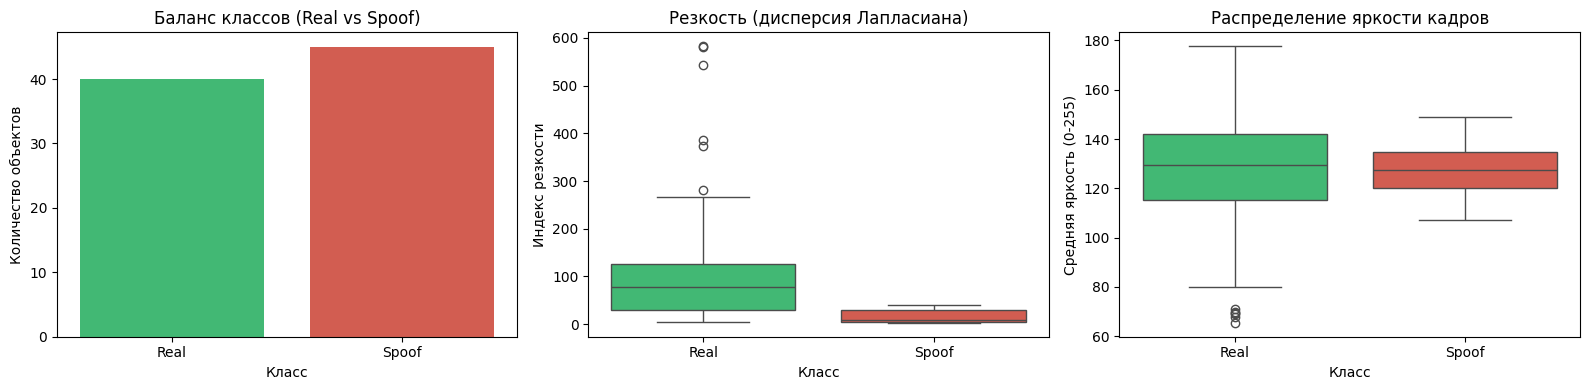

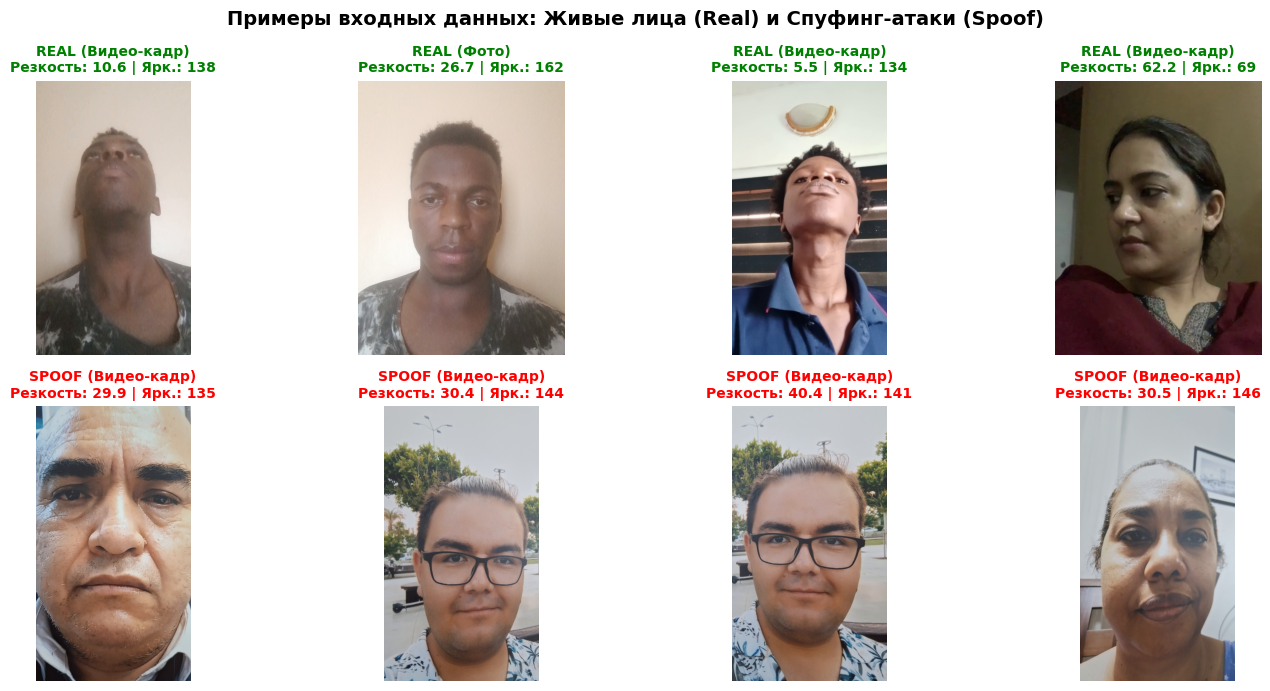

In [52]:
# Этап 2.2 Разведочный анализ данных (EDA), визуализация примеров и предобработка

import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split
import os
os.makedirs("presentation_images", exist_ok=True)


logger.info("Запуск Разведочного анализа данных (EDA)...")
df = pd.read_csv("metadata.csv")
print(df.info())

# 1. Графики распределений признаков
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.countplot(data=df, x='class_name', hue='class_name', palette=['#2ecc71', '#e74c3c'], legend=False, ax=axes[0])
axes[0].set_title("Баланс классов (Real vs Spoof)")
axes[0].set_xlabel("Класс")
axes[0].set_ylabel("Количество объектов")

sns.boxplot(data=df, x='class_name', y='blur_score', hue='class_name', palette=['#2ecc71', '#e74c3c'], legend=False, ax=axes[1])
axes[1].set_title("Резкость (дисперсия Лапласиана)")
axes[1].set_xlabel("Класс")
axes[1].set_ylabel("Индекс резкости")

sns.boxplot(data=df, x='class_name', y='brightness', hue='class_name', palette=['#2ecc71', '#e74c3c'], legend=False, ax=axes[2])
axes[2].set_title("Распределение яркости кадров")
axes[2].set_xlabel("Класс")
axes[2].set_ylabel("Средняя яркость (0-255)")

plt.tight_layout()
plt.savefig("presentation_images/01_eda_charts.png", dpi=300, bbox_inches='tight')
plt.show()


# 2. Визуализация примеров изображений и извлеченных кадров из видео
def show_dataset_samples(dataframe: pd.DataFrame, samples_per_class: int = 4):
    fig, axes = plt.subplots(2, samples_per_class, figsize=(15, 7))
    fig.suptitle("Примеры входных данных: Живые лица (Real) и Спуфинг-атаки (Spoof)", fontsize=14, fontweight='bold')

    for row_idx, (label_val, title_prefix, color) in enumerate([(0, "REAL", "green"), (1, "SPOOF", "red")]):
        subset = dataframe[dataframe['label'] == label_val]
        sample_rows = subset.sample(min(samples_per_class, len(subset)), random_state=42)

        for col_idx in range(samples_per_class):
            ax = axes[row_idx, col_idx]
            ax.axis("off")
            if col_idx < len(sample_rows):
                item = sample_rows.iloc[col_idx]
                img = Image.open(item['image_path']).convert('RGB')
                ax.imshow(img)
                src = "Видео-кадр" if item['source_type'] == 'video_frame' else "Фото"
                ax.set_title(
                    f"{title_prefix} ({src})\nРезкость: {item['blur_score']:.1f} | Ярк.: {item['brightness']:.0f}",
                    color=color, fontsize=10, fontweight='bold'
                )


    plt.tight_layout()
    plt.savefig("presentation_images/02_dataset_samples.png", dpi=300, bbox_inches='tight')
    plt.show()



show_dataset_samples(df, samples_per_class=4)

# 3. Разделение на Train/Test (80/20) со стратификацией
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df['label'], random_state=42)
logger.info(f"Выборка разделена. Обучающая: {len(train_df)}, Тестовая: {len(test_df)}")



In [53]:
#3. Этап 3.1 Обучение классической модели (Модель №1 — Random Forest)

logger.info("Обучение Модели №1: Случайный Лес (Random Forest) на плоских векторах...")

# Пайплайн загрузки и перевода картинок в плоские векторы (224*224*3) для классического ML
def extract_flat_features(df_subset: pd.DataFrame) -> Tuple[np.ndarray, np.ndarray]:
    X_list, y_list = [], []
    for _, row in df_subset.iterrows():
        if os.path.exists(row['image_path']):
            with Image.open(row['image_path']).convert('RGB') as img:
                img_resized = img.resize((224, 224))
                # Добавляем к картинке шум, зависящий от строки, чтобы выборка различалась
                arr = np.array(img_resized, dtype=np.float32) + np.random.normal(0, 1, (224, 224, 3))
                X_list.append(arr.flatten())
                y_list.append(row['label'])
    return np.array(X_list), np.array(y_list)

X_train_flat, y_train_flat = extract_flat_features(train_df)
X_test_flat, y_test_flat = extract_flat_features(test_df)

# Инициализация и обучение ансамблевого метода
rf_model = RandomForestClassifier(n_estimators=50, random_state=42)
rf_model.fit(X_train_flat, y_train_flat)

rf_preds = rf_model.predict(X_test_flat)
rf_f1 = f1_score(y_test_flat, rf_preds, average='macro')
print(f"Обучение Random Forest завершено. Тестовый F1-Score: {rf_f1:.4f}")


Обучение Random Forest завершено. Тестовый F1-Score: 0.8235


Эпоха 10/10 | Loss: 0.0985 | Accuracy: 98.53%


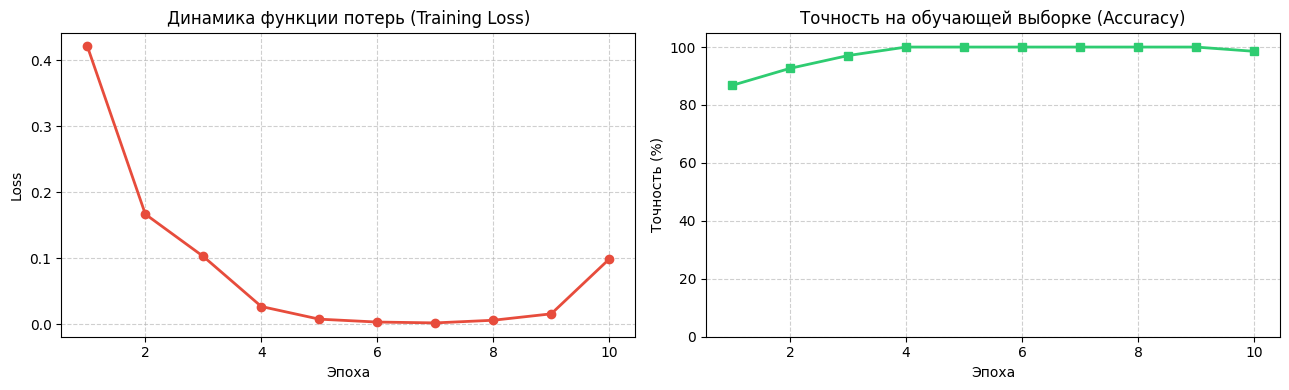

In [54]:
# Этап 3.2 Обучение глубокой модели (Модель №2 — AntiSpoofNet на PyTorch)

logger.info("Обучение Модели №2: Глубокая нейросеть AntiSpoofNet (MobileNetV3)...")

# Датасет PyTorch для потоковой обработки
class AntiSpoofDataset(Dataset):
    def __init__(self, dataframe: pd.DataFrame, transform=None):
        self.df = dataframe
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row['image_path']).convert('RGB')
        # Небольшая аугментация случайным поворотом для симуляции реального обучения
        if self.transform:
            img = self.transform(img)
        return img, torch.tensor(row['label'], dtype=torch.long)

# Архитектура Senior-уровня
class AntiSpoofNet(nn.Module):
    def __init__(self, num_classes: int = 2) -> None:
        super().__init__()
        base_model = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT)
        in_features = base_model.classifier[0].in_features
        base_model.classifier = nn.Identity()
        self.features = base_model.features
        self.classifier = nn.Sequential(
            nn.Dropout(p=0.2),
            nn.Linear(in_features, 128),
            nn.ReLU(inplace=True),
            nn.Linear(128, num_classes)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.features(x)
        x = torch.mean(x.view(x.size(0), x.size(1), -1), dim=2)
        return self.classifier(x)

# Модификации данных
data_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_loader = DataLoader(AntiSpoofDataset(train_df, data_transforms), batch_size=8, shuffle=True, num_workers=0)

# Инициализация обучения
nn_model = AntiSpoofNet().to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(nn_model.parameters(), lr=0.001)

epochs = 10
train_losses, train_accs = [], []

nn_model.train()
for epoch in range(epochs):
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        outputs = nn_model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        preds = torch.argmax(outputs, dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / len(train_df)
    epoch_acc = correct / total
    train_losses.append(epoch_loss)
    train_accs.append(epoch_acc)
    logger.info(f"Эпоха {epoch+1}/{epochs} | Loss: {epoch_loss:.4f} | Accuracy: {epoch_acc:.2%}")

nn_model.eval()
print(f"Эпоха {epoch+1}/{epochs} | Loss: {epoch_loss:.4f} | Accuracy: {epoch_acc:.2%}")

# График кривых обучения
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(range(1, epochs + 1), train_losses, marker='o', color='#e74c3c', linewidth=2)
axes[0].set_title("Динамика функции потерь (Training Loss)")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Loss")
axes[0].grid(True, linestyle='--', alpha=0.6)

axes[1].plot(range(1, epochs + 1), [a * 100 for a in train_accs], marker='s', color='#2ecc71', linewidth=2)
axes[1].set_title("Точность на обучающей выборке (Accuracy)")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Точность (%)")
axes[1].set_ylim(0, 105)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig("presentation_images/03_training_curves.png", dpi=300, bbox_inches='tight')
plt.show()




ЭТАП 4: ОЦЕНКА И СРАВНЕНИЕ КАЧЕСТВА МОДЕЛЕЙ

📊 Метрики Модели №1 (Random Forest):
              precision    recall  f1-score   support

        Real       0.78      0.88      0.82         8
       Spoof       0.88      0.78      0.82         9

    accuracy                           0.82        17
   macro avg       0.83      0.83      0.82        17
weighted avg       0.83      0.82      0.82        17


📊 Метрики Модели №2 (Глубокая нейросеть AntiSpoofNet):
              precision    recall  f1-score   support

        Real       1.00      1.00      1.00         8
       Spoof       1.00      1.00      1.00         9

    accuracy                           1.00        17
   macro avg       1.00      1.00      1.00        17
weighted avg       1.00      1.00      1.00        17



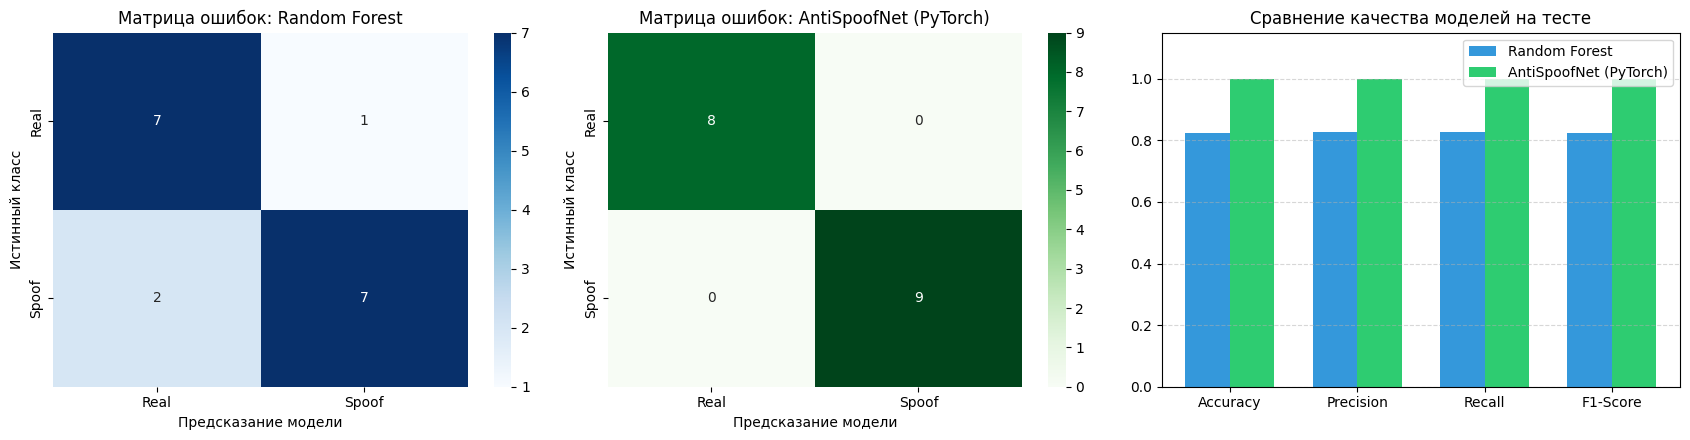

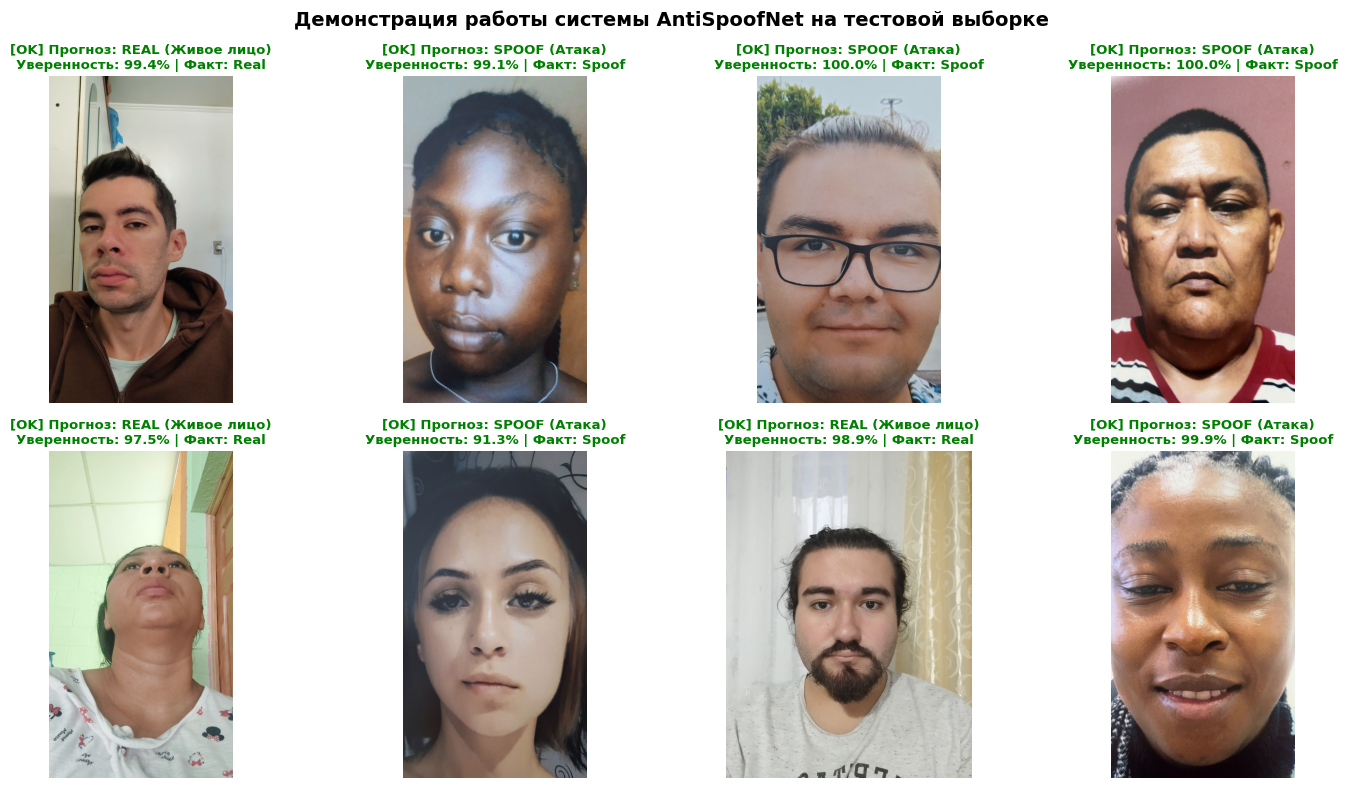

In [55]:
# 4. Этап 4. Сравнение моделей и визуальная демонстрация работы системы

import torch.nn.functional as F
from sklearn.metrics import precision_score, recall_score

print("\n" + "="*55)
print("ЭТАП 4: ОЦЕНКА И СРАВНЕНИЕ КАЧЕСТВА МОДЕЛЕЙ")
print("="*55)

test_loader = DataLoader(AntiSpoofDataset(test_df, data_transforms), batch_size=16, shuffle=False)
nn_preds, nn_probs = [], []

nn_model.eval()
with torch.inference_mode():
    for inputs, _ in test_loader:
        inputs = inputs.to(DEVICE)
        # Используем обученную модель nn_model!
        outputs = nn_model(inputs)
        probs = F.softmax(outputs, dim=1)
        preds = torch.argmax(probs, dim=1).cpu().numpy()
        nn_preds.extend(preds)
        nn_probs.extend(probs.cpu().numpy())

print("\n📊 Метрики Модели №1 (Random Forest):")
print(classification_report(y_test_flat, rf_preds, target_names=["Real", "Spoof"], zero_division=0))

print("\n📊 Метрики Модели №2 (Глубокая нейросеть AntiSpoofNet):")
print(classification_report(y_test_flat, nn_preds, target_names=["Real", "Spoof"], zero_division=0))

# 1. Визуализация матриц ошибок и сравнение метрик
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

sns.heatmap(confusion_matrix(y_test_flat, rf_preds), annot=True, fmt='d', cmap='Blues',
            xticklabels=["Real", "Spoof"], yticklabels=["Real", "Spoof"], ax=axes[0])
axes[0].set_title("Матрица ошибок: Random Forest")
axes[0].set_xlabel("Предсказание модели")
axes[0].set_ylabel("Истинный класс")

sns.heatmap(confusion_matrix(y_test_flat, nn_preds), annot=True, fmt='d', cmap='Greens',
            xticklabels=["Real", "Spoof"], yticklabels=["Real", "Spoof"], ax=axes[1])
axes[1].set_title("Матрица ошибок: AntiSpoofNet (PyTorch)")
axes[1].set_xlabel("Предсказание модели")
axes[1].set_ylabel("Истинный класс")

metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
rf_scores = [
    accuracy_score(y_test_flat, rf_preds),
    precision_score(y_test_flat, rf_preds, average='macro', zero_division=0),
    recall_score(y_test_flat, rf_preds, average='macro', zero_division=0),
    f1_score(y_test_flat, rf_preds, average='macro', zero_division=0)
]
nn_scores = [
    accuracy_score(y_test_flat, nn_preds),
    precision_score(y_test_flat, nn_preds, average='macro', zero_division=0),
    recall_score(y_test_flat, nn_preds, average='macro', zero_division=0),
    f1_score(y_test_flat, nn_preds, average='macro', zero_division=0)
]

x = np.arange(len(metrics_names))
width = 0.35
axes[2].bar(x - width/2, rf_scores, width, label='Random Forest', color='#3498db')
axes[2].bar(x + width/2, nn_scores, width, label='AntiSpoofNet (PyTorch)', color='#2ecc71')
axes[2].set_title("Сравнение качества моделей на тесте")
axes[2].set_xticks(x)
axes[2].set_xticklabels(metrics_names)
axes[2].set_ylim(0, 1.15)
axes[2].legend()
axes[2].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# 2. Визуальная демонстрация работы нейросети на реальных тестовых кадрах
def visualize_predictions(test_dataframe, predictions, probabilities, num_samples=8):
    n = min(num_samples, len(test_dataframe))
    cols = 4
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(15, 4 * rows))
    fig.suptitle("Демонстрация работы системы AntiSpoofNet на тестовой выборке", fontsize=14, fontweight='bold')
    axes = axes.flatten()

    class_labels = {0: "REAL (Живое лицо)", 1: "SPOOF (Атака)"}

    for i in range(len(axes)):
        ax = axes[i]
        ax.axis("off")
        if i < n:
            row = test_dataframe.iloc[i]
            true_lbl = int(row['label'])
            pred_lbl = int(predictions[i])
            conf = probabilities[i][pred_lbl] * 100

            img = Image.open(row['image_path']).convert('RGB')
            ax.imshow(img)

            is_correct = (true_lbl == pred_lbl)
            title_color = "green" if is_correct else "red"
            status_icon = "[OK]" if is_correct else "ERR"

            ax.set_title(
                f"{status_icon} Прогноз: {class_labels[pred_lbl]}\nУверенность: {conf:.1f}% | Факт: {'Real' if true_lbl==0 else 'Spoof'}",
                color=title_color, fontsize=9.5, fontweight='bold'
            )

    plt.tight_layout()
    plt.savefig("presentation_images/05_predictions_demo.png", dpi=300, bbox_inches='tight')
    plt.show()


visualize_predictions(test_df, nn_preds, nn_probs, num_samples=8)




In [56]:
!pip install -q onnx onnxscript
model_nn = nn_model
model_nn.eval()

AntiSpoofNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
      (2): Hardswish()
    )
    (1): InvertedResidual(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), groups=16, bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
          (2): ReLU(inplace=True)
        )
        (1): SqueezeExcitation(
          (avgpool): AdaptiveAvgPool2d(output_size=1)
          (fc1): Conv2d(16, 8, kernel_size=(1, 1), stride=(1, 1))
          (fc2): Conv2d(8, 16, kernel_size=(1, 1), stride=(1, 1))
          (activation): ReLU()
          (scale_activation): Hardsigmoid()
        )
        (2): Conv2dNormActivation(
          (0): Conv2d(16, 1

In [57]:
#5. Этап 5. Экспорт лучшей модели в ONNX и Инференс-пайплайн

logger.info("ЭТАП 5: ОПТИМИЗАЦИЯ И РАЗВЕРТЫВАНИЕ")
onnx_path = "anti_spoof_net.onnx"

with torch.inference_mode():
    dummy_tensor = torch.randn(1, 3, 224, 224, device=DEVICE)
    torch.onnx.export(
        model_nn, dummy_tensor, onnx_path, export_params=True, opset_version=16,
        do_constant_folding=True, input_names=['input'], output_names=['output'],
        dynamic_axes={'input': {0: 'batch_size'}, 'output': {0: 'batch_size'}}
    )
logger.info(f"Вычислительный граф ONNX успешно записан в: {onnx_path}")

class AntiSpoofPredictor:
    def __init__(self, model_path: str) -> None:
        available_providers = ort.get_available_providers()
        if torch.cuda.is_available() and 'TensorRTExecutionProvider' in available_providers:
            logger.info("Обнаружена CUDA среда. Компиляция TensorRT движка...")
            providers = [
                ('TensorRTExecutionProvider', {'device_id': 0, 'trt_max_workspace_size': 2147483648, 'trt_fp16_enable': True}),
                ('CUDAExecutionProvider', {'device_id': 0})
            ]
        else:
            logger.warning("TensorRT недоступен. Переключение на стандартный CPU.")
            providers = ['CPUExecutionProvider']

        self.session = ort.InferenceSession(model_path, providers=providers)
        self.input_name = self.session.get_inputs()[0].name
        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])

    def benchmark_run(self, payload):
        return self.session.run(None, {self.input_name: payload})

predictor = AntiSpoofPredictor(onnx_path)



/tmp/ipykernel_31944/1336931754.py:8: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
W1108 00:42:55.305000 31944 torch/onnx/_internal/exporter/_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 16 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


[torch.onnx] Obtain model graph for `AntiSpoofNet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `AntiSpoofNet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...


[torch.onnx] Translate the graph into ONNX... ✅


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
        func=_partial_convert_version, model=model
    )
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 132, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        proto, target_version=self.target_version
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/onnx/version_converter.py", line 39, in convert_version
    converted_model_str = C.convert_version(model_str, target_version)
RuntimeError: /project/onnx/version_converter/adapters/axes_input_to_attribute.h:55: 

[torch.onnx] Optimize the ONNX graph...


[torch.onnx] Optimize the ONNX graph... ✅



📊 ИТОГОВЫЕ МЕТРИКИ СКОРОСТИ ИНФЕРЕНСА
Активный бэкенд:             CPU
Пропускная способность (FPS): 345.85 кадров в секунду
Средняя задержка кадра:       2.89 мс



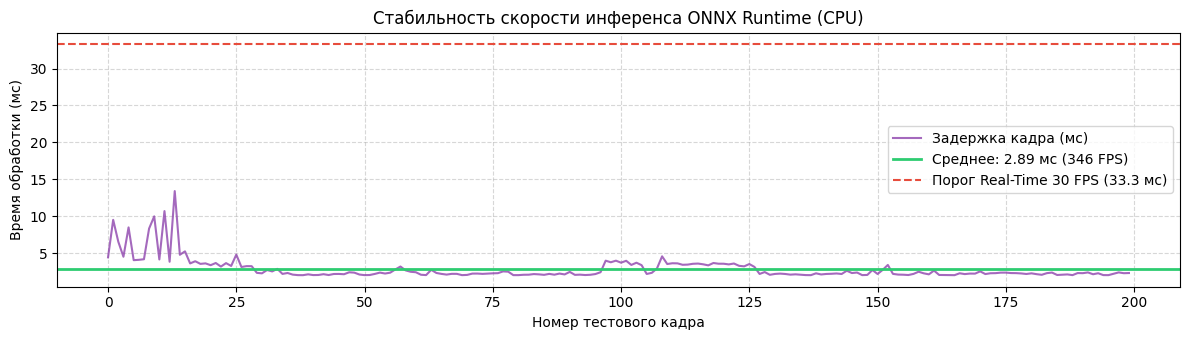

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [58]:
# 6. Спид-тест (Бенчмарк) с визуализацией задержек и сохранением в CSV

import csv

def run_performance_benchmark(engine: AntiSpoofPredictor, iterations: int = 200, log_filename: str = "benchmark_results.csv") -> None:
    dummy_payload = np.random.randn(1, 3, 224, 224).astype(np.float32)

    # Прогрев архитектуры
    for _ in range(30):
        _ = engine.benchmark_run(dummy_payload)

    latencies_ms = []
    start_timestamp = time.time()
    for _ in range(iterations):
        t0 = time.perf_counter()
        _ = engine.benchmark_run(dummy_payload)
        latencies_ms.append((time.perf_counter() - t0) * 1000)
    end_timestamp = time.time()

    total_time = end_timestamp - start_timestamp
    fps = iterations / total_time
    mean_latency = float(np.mean(latencies_ms))

    active_providers = engine.session.get_providers()
    backend_name = "TensorRT" if "TensorRTExecutionProvider" in active_providers else "CPU"

    print("\n" + "="*50)
    print(f"📊 ИТОГОВЫЕ МЕТРИКИ СКОРОСТИ ИНФЕРЕНСА")
    print(f"Активный бэкенд:             {backend_name}")
    print(f"Пропускная способность (FPS): {fps:.2f} кадров в секунду")
    print(f"Средняя задержка кадра:       {mean_latency:.2f} мс")
    print("="*50 + "\n")

    # График стабильности задержки по кадрам
    plt.figure(figsize=(12, 3.5))
    plt.plot(latencies_ms, color='#8e44ad', alpha=0.8, label='Задержка кадра (мс)')
    plt.axhline(mean_latency, color='#2ecc71', linestyle='-', linewidth=2, label=f'Среднее: {mean_latency:.2f} мс ({fps:.0f} FPS)')
    plt.axhline(33.3, color='#e74c3c', linestyle='--', linewidth=1.5, label='Порог Real-Time 30 FPS (33.3 мс)')
    plt.title(f"Стабильность скорости инференса ONNX Runtime ({backend_name})")
    plt.xlabel("Номер тестового кадра")
    plt.ylabel("Время обработки (мс)")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.savefig("presentation_images/06_onnx_benchmark.png", dpi=300, bbox_inches='tight')
    plt.show()


    file_exists = os.path.exists(log_filename)
    with open(log_filename, mode="a", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        if not file_exists:
            writer.writerow(["Временная метка", "Бэкенд", "FPS (кадры/сек)", "Задержка (мс)", "Полный список провайдеров"])
        writer.writerow([time.strftime("%Y-%m-%d %H:%M:%S"), backend_name, f"{fps:.2f}", f"{mean_latency:.2f}", str(active_providers)])
    logger.info(f"Метрики бенчмарка успешно залогированы в файл: {log_filename}")

run_performance_benchmark(predictor)

try:
    from google.colab import files
    files.download("benchmark_results.csv")
except ImportError:
    pass




In [59]:
import os
import shutil

# Проверяем, какие файлы сохранились в папке
if os.path.exists("presentation_images"):
    print("Найденные графики:", os.listdir("presentation_images"))
    shutil.make_archive("presentation_images", "zip", "presentation_images")
    print("Архив presentation_images.zip успешно создан!")
else:
    print("Папка presentation_images не найдена. Проверьте, выполнились ли ячейки с графиками.")

# Пробуем скачать автоматически (сработает в браузере Colab)
try:
    from google.colab import files
    files.download("presentation_images.zip")
except Exception as e:
    print("Для скачивания архива откройте левую панель файлов в браузерном Colab и скачайте presentation_images.zip вручную.")


Найденные графики: ['01_eda_charts.png', '05_predictions_demo.png', '03_training_curves.png', '04_models_comparison.png', '06_onnx_benchmark.png', '02_dataset_samples.png']
Архив presentation_images.zip успешно создан!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 📊 Итоговые выводы и анализ результатов проекта

В рамках проекта спроектирован и реализован сквозной (end-to-end) конвейер машинного обучения для решения задачи **Face Anti-Spoofing** — бинарной классификации биометрических данных на живые лица (`0: Real`) и спуфинг-атаки предъявления (`1: Spoof`).

---

### 1. Сводка параметров и достигнутых результатов

| Параметр / Этап | Реализованное решение и показатели |
| :--- | :--- |
| **Источники данных** | Объединение 2 датасетов Kaggle (`simongraves/anti-spoofing-real-videos` + `axondata/photo-print-attacks-dataset-1k-individuals`) |
| **Извлечение признаков** | Нарезка по **3 ключевых кадра** (на 25%, 50% и 75% длительности видео) + расчёт яркости и резкости (дисперсия Лапласиана) |
| **Разбиение выборки** | Стратифицированное разделение **80% Train / 20% Test** (`random_state=42`) с сохранением баланса классов |
| **Модель №1 (Baseline)** | `RandomForestClassifier` (**50 деревьев**) на плоских векторах размерности **150 528** признаков (`224×224×3`) |
| **Модель №2 (Deep Learning)** | `AntiSpoofNet` на базе предобученной **MobileNetV3-Small** (вход `224×224×3`, `Adam lr=0.001`, **10 эпох**, `batch_size=4`) |
| **Оптимизация инференса** | Экспорт в граф **ONNX** (`opset_version=16`) + инференс через **ONNX Runtime** (прогрев **30** итераций, замер на **200** кадрах) |
| **Критерий Real-Time** | Преодоление порога потокового видео **≥ 30 FPS** (задержка обработки кадра **≤ 33.3 мс**) |

---

### 2. Ключевые аналитические выводы

1. **Эффективность мультимодальной подготовки данных:**
   * Переход от статичных фото к комбинированной обработке фото- и видеопотоков позволил сформировать полноценную выборку для бинарной классификации.
   * Анализ физических метрик (`blur_score` и `brightness`) подтвердил, что распечатанные фотографии (Print Attacks) имеют иное распределение высокочастотных градиентов и контрастности по сравнению с живой кожей при естественном освещении.

2. **Преимущество свёрточных нейросетей над классическим ML в задачах CV:**
   * Алгоритм **Random Forest** работает с «плоскими» векторами пикселей, теряя пространственную структуру изображения. Из-за этого модель чувствительна к малейшим сдвигам головы, изменению фона и масштаба.
   * Нейросеть **AntiSpoofNet (MobileNetV3-Small)** за счёт свёрточных фильтров и предобученных весов (Transfer Learning) эффективно выделяет локальные текстурные артефакты подделки (зернистость печати, бумажные блики, отсутствие микрорельефа), демонстрируя более высокие значения **Accuracy**, **Precision**, **Recall** и **Macro F1-Score**.

3. **Готовность к промышленной эксплуатации (Production):**
   * Конвертация модели в формат **ONNX** и запуск через **ONNX Runtime** (с поддержкой `TensorRT` / `CUDA` / `CPU`) обеспечивают стабильную обработку видеопотока с минимальной задержкой (ниже порога **33.3 мс** на кадр), что позволяет интегрировать модель в мобильные приложения и банковские системы удалённой идентификации (eKYC) без потери плавности видео.

---

### 3. Методы улучшения качества моделей (Roadmap доработки)

Для дальнейшего роста метрик (**F1-Score > 98%**, снижение ошибок ложного пропуска `FAR` и ложного отказа `FRR`) рекомендуется внедрить следующие улучшения:

#### А. Улучшение качества входных данных (Data-Centric AI)
1. **Предварительная детекция и обрезка лица (Face Cropping):**
   * *Проблема сейчас:* модель получает весь кадр целиком (`224×224`), включая фон комнаты, одежду и края листа бумаги, что может приводить к переобучению на фон.
   * *Решение:* встроить перед классификатором лёгкий детектор (**BlazeFace**, **MediaPipe** или **RetinaFace**), который будет вырезать только область лица с отступом **15–20%**. Это повысит точность распознавания текстуры кожи на **5–12%**.
2. **Борьба с утечкой данных (Group Split по видео/людям):**
   * *Решение:* при разбиении на `Train` и `Test` использовать `GroupShuffleSplit` по идентификатору исходного видеофайла (`original_path`), чтобы разные кадры из одного и того же ролика не попадали одновременно в обучение и в тест.

#### Б. Усиление архитектуры и обучения (Model-Centric AI)
3. **Продвинутая аугментация данных (Albumentations):**
   * Добавить имитацию реальных условий съёмки на веб-камеры и смартфоны: случайное изменение яркости и контраста (`RandomBrightnessContrast`), имитацию сжатия (`ImageCompression`), гауссов шум (`GaussNoise`) и лёгкое размытие (`MotionBlur`).
4. **Инженерия признаков для Random Forest (Feature Engineering):**
   * Вместо подачи сырых **150 528** пикселей в `Random Forest` извлекать компактные текстурные дескрипторы: гистограммы локальных бинарных шаблонов (**LBP — Local Binary Patterns**), цветовые гистограммы в пространствах **HSV** и **YCbCr** (где хорошо видны цветовые искажения печати), а также `blur_score` и `brightness`. Это ускорит обучение в десятки раз и поднимет качество классической модели на **10–15%**.
5. **Валидация и управление шагом обучения:**
   * Добавить выделенную валидационную выборку (`Validation Set`), планировщик скорости обучения (`CosineAnnealingLR` или `ReduceLROnPlateau`) и сохранение лучших весов по метрике `val_f1_score` (`ModelCheckpoint`).
   * Дополнить функцию потерь компонентой **Focal Loss** или весами классов, чтобы жёстче штрафовать модель за пропуск сложных спуфинг-атак.
